<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Trees = Learning a flowchart from data
#### In this file I walk through how I built a decision tree **from scratch**, and then compare it with scikit-learn.

A decision tree is a set of yes/no questions. At every node I pick the question that splits the data into the "cleanest" groups, then repeat on each group until the groups are (almost) pure.

The example problem from the course: I grow mushrooms and want to predict **edible (1) or poisonous (0)** from three features. *(Toy data for learning only - never use this to decide what to eat!)*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## The dataset
10 mushrooms, three one-hot encoded features:

| column | 1 means | 0 means |
|---|---|---|
| Brown cap | brown cap | red cap |
| Tapering stalk | tapering stalk | enlarging stalk |
| Solitary | grows alone | grows in groups |

In [2]:
X_train = np.array([[1,1,1],[1,0,1],[1,0,0],[1,0,0],[1,1,1],[0,1,1],[0,0,0],[1,0,1],[0,1,0],[1,0,0]])
y_train = np.array([1,1,0,0,1,0,0,1,1,0])
feature_names = ["Brown cap", "Tapering stalk", "Solitary"]
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("Edible fraction:", y_train.mean())

X_train: (10, 3)  y_train: (10,)
Edible fraction: 0.5


## Step 1 - Entropy: how mixed is a node?
Entropy measures impurity. With $p_1$ = fraction of edible mushrooms in a node:

$$H(p_1) = -p_1\log_2(p_1) - (1-p_1)\log_2(1-p_1)$$

- All edible or all poisonous -> $H = 0$ (pure, nothing left to decide)
- Half and half -> $H = 1$ (maximally confused)

By convention $0\log_2 0 = 0$, so I handle $p_1 = 0$ and $p_1 = 1$ separately.

Root entropy: 1.0
Pure node   : 0.0


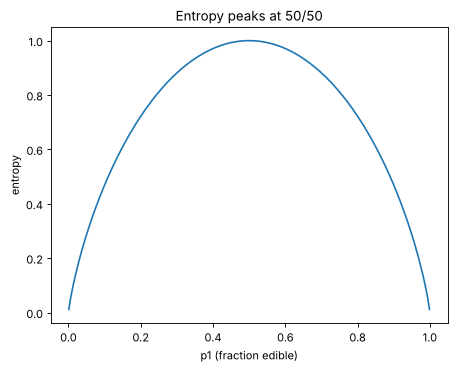

In [3]:
def compute_entropy(y):
    if len(y) == 0:
        return 0.0
    p1 = np.mean(y == 1)
    if p1 == 0 or p1 == 1:
        return 0.0
    return -p1 * np.log2(p1) - (1 - p1) * np.log2(1 - p1)

p = np.linspace(0.001, 0.999, 200)
plt.plot(p, -p*np.log2(p) - (1-p)*np.log2(1-p))
plt.xlabel("p1 (fraction edible)"); plt.ylabel("entropy"); plt.title("Entropy peaks at 50/50")
plt.show()
print("Root entropy:", compute_entropy(y_train))       # 5 edible / 5 poisonous -> 1.0
print("Pure node   :", compute_entropy(np.array([1,1,1])))

## Step 2 - Split a node on a feature
Given the indices of the examples currently at a node and a feature, return the left branch (feature = 1) and right branch (feature = 0).

In [4]:
def split_dataset(X, node_indices, feature):
    left, right = [], []
    for i in node_indices:
        (left if X[i, feature] == 1 else right).append(i)
    return left, right

root = list(range(len(X_train)))
l, r = split_dataset(X_train, root, 0)
print("Split on 'Brown cap' -> left:", l, " right:", r)

Split on 'Brown cap' -> left: [0, 1, 2, 3, 4, 7, 9]  right: [5, 6, 8]


## Step 3 - Information gain: how much did the split help?
Compare the entropy before the split with the **weighted** average entropy after it:

$$IG = H(p_1^{node}) - \left(w_{left}\,H(p_1^{left}) + w_{right}\,H(p_1^{right})\right)$$

where $w_{left}$ is the fraction of the node's examples that went left. A bigger gain = a better question.

In [5]:
def compute_information_gain(X, y, node_indices, feature):
    left, right = split_dataset(X, node_indices, feature)
    y_node = y[node_indices]
    w_left  = len(left)  / len(node_indices)
    w_right = len(right) / len(node_indices)
    weighted = w_left * compute_entropy(y[left]) + w_right * compute_entropy(y[right])
    return compute_entropy(y_node) - weighted

for f in range(3):
    print(f"Information gain splitting on '{feature_names[f]}': {compute_information_gain(X_train, y_train, root, f):.4f}")

Information gain splitting on 'Brown cap': 0.0349
Information gain splitting on 'Tapering stalk': 0.1245
Information gain splitting on 'Solitary': 0.2781


## Step 4 - Pick the best feature
Just try every feature and keep the one with the highest gain (return -1 if there is nothing left to split on).

In [6]:
def get_best_split(X, y, node_indices):
    best_feature, best_gain = -1, 0
    for f in range(X.shape[1]):
        gain = compute_information_gain(X, y, node_indices, f)
        if gain > best_gain:
            best_feature, best_gain = f, gain
    return best_feature

print("Best first split:", feature_names[get_best_split(X_train, y_train, root)])

Best first split: Solitary


## Step 5 - Build the tree recursively
Stop when `max_depth` is reached (or when the node is pure / nothing helps). Otherwise pick the best split and recurse on both branches. I store the tree as nested dicts so I can print it and use it for prediction.

In [7]:
def build_tree(X, y, node_indices, depth=0, max_depth=2):
    labels = y[node_indices]
    best = get_best_split(X, y, node_indices)
    if depth == max_depth or best == -1 or compute_entropy(labels) == 0:
        return {"leaf": True, "prediction": int(round(labels.mean())) if len(labels) else 0,
                "n": len(node_indices), "p_edible": float(labels.mean()) if len(labels) else 0.0}
    left, right = split_dataset(X, node_indices, best)
    return {"leaf": False, "feature": best,
            "left":  build_tree(X, y, left,  depth + 1, max_depth),
            "right": build_tree(X, y, right, depth + 1, max_depth)}

def print_tree(node, indent=""):
    if node["leaf"]:
        label = "EDIBLE" if node["prediction"] == 1 else "POISONOUS"
        print(f"{indent}-> {label}  (n={node['n']}, p_edible={node['p_edible']:.2f})")
    else:
        print(f"{indent}{feature_names[node['feature']]}?")
        print(f"{indent} yes:"); print_tree(node["left"],  indent + "    ")
        print(f"{indent} no:");  print_tree(node["right"], indent + "    ")

tree = build_tree(X_train, y_train, root, max_depth=2)
print_tree(tree)

Solitary?
 yes:
    Brown cap?
     yes:
        -> EDIBLE  (n=4, p_edible=1.00)
     no:
        -> POISONOUS  (n=1, p_edible=0.00)
 no:
    Tapering stalk?
     yes:
        -> EDIBLE  (n=1, p_edible=1.00)
     no:
        -> POISONOUS  (n=4, p_edible=0.00)


Now use it to predict, and check it on the training data.

In [8]:
def predict_one(node, x):
    while not node["leaf"]:
        node = node["left"] if x[node["feature"]] == 1 else node["right"]
    return node["prediction"]

preds = np.array([predict_one(tree, x) for x in X_train])
print("Train accuracy:", (preds == y_train).mean())
print("Brown cap, enlarging stalk, solitary ->", predict_one(tree, [1, 0, 1]))

Train accuracy: 1.0
Brown cap, enlarging stalk, solitary -> 1


## The scikit-learn version
`criterion='entropy'` makes sklearn use the same measure I just implemented (its default is Gini impurity, which behaves very similarly).

In [9]:
from sklearn.tree import DecisionTreeClassifier, export_text

clf = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=0).fit(X_train, y_train)
print(export_text(clf, feature_names=feature_names))
print("sklearn train accuracy:", clf.score(X_train, y_train))

|--- Solitary <= 0.50
|   |--- Tapering stalk <= 0.50
|   |   |--- class: 0
|   |--- Tapering stalk >  0.50
|   |   |--- class: 1
|--- Solitary >  0.50
|   |--- Brown cap <= 0.50
|   |   |--- class: 0
|   |--- Brown cap >  0.50
|   |   |--- class: 1

sklearn train accuracy: 1.0


## What happens when I let the tree grow?
Depth controls complexity. With no limit a tree keeps splitting until every leaf is pure - it memorizes the training set. I will use a noisier, bigger dataset to *see* this.

best test depth: 2 | test acc: 0.9


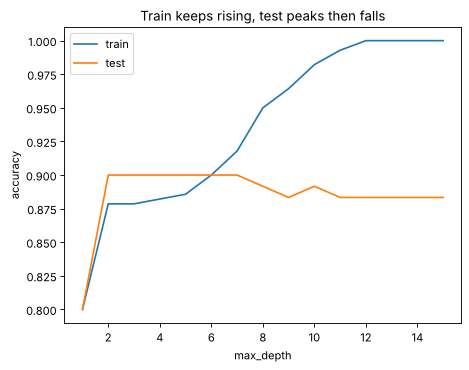

In [10]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

Xm, ym = make_moons(n_samples=400, noise=0.35, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.3, random_state=0)

depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0).fit(Xtr, ytr)
    train_acc.append(m.score(Xtr, ytr)); test_acc.append(m.score(Xte, yte))

plt.plot(depths, train_acc, label="train"); plt.plot(depths, test_acc, label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.title("Train keeps rising, test peaks then falls")
plt.show()
print("best test depth:", list(depths)[int(np.argmax(test_acc))], "| test acc:", max(test_acc))

That gap between train and test is **overfitting**. A single deep tree is also *unstable*: change a few training rows and the whole tree can look different. The standard fix is to average many trees - a random forest.

In [11]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xtr, ytr)
deep = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(Xtr, ytr)
print(f"unlimited-depth tree : train {deep.score(Xtr, ytr):.2f} | test {deep.score(Xte, yte):.2f}")
print(f"random forest        : train {rf.score(Xtr, ytr):.2f} | test {rf.score(Xte, yte):.2f}")

unlimited-depth tree : train 1.00 | test 0.88
random forest        : train 1.00 | test 0.90


## Drawbacks / things to remember
- **Overfits easily** if depth is not limited (use `max_depth`, `min_samples_leaf`, or pruning).
- **High variance** - small data changes can produce a very different tree. Ensembles (random forest, gradient boosting) fix this.
- **Greedy** - each split is chosen for the best gain *right now*, not for the best final tree.
- **Axis-aligned splits only** - diagonal boundaries need many splits.
- **Continuous features** need a threshold search (try midpoints between sorted values); my one-hot version skipped that.
- Big plus: it is **easy to read and explain**, needs no feature scaling, and handles mixed feature types.